In [1]:
# Set up the standalone preprocessing notebook and load the audited BRISC manifests.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Project paths
PROJECT_ROOT = Path("/Users/krittikaroy/Brain Tumor")
DATASET_ROOT = PROJECT_ROOT / "data" / "brisc2025"
PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"
OUTPUTS_ROOT = PROJECT_ROOT / "outputs"

TABLES_ROOT = OUTPUTS_ROOT / "tables"
FIGURES_ROOT = OUTPUTS_ROOT / "figures"

TABLES_ROOT.mkdir(parents=True, exist_ok=True)
FIGURES_ROOT.mkdir(parents=True, exist_ok=True)

# Final classification manifests from Notebook 04
TRAIN_MANIFEST_PATH = PROCESSED_ROOT / "classification_train_manifest.csv"
VALIDATION_MANIFEST_PATH = PROCESSED_ROOT / "classification_validation_manifest.csv"
TEST_MANIFEST_PATH = PROCESSED_ROOT / "classification_test_manifest.csv"
MASTER_SPLIT_PATH = PROCESSED_ROOT / "classification_final_split_manifest.csv"

# Original BRISC manifest
RAW_MANIFEST_PATH = DATASET_ROOT / "manifest.csv"

# Check that all required files exist
required_files = [
    TRAIN_MANIFEST_PATH,
    VALIDATION_MANIFEST_PATH,
    TEST_MANIFEST_PATH,
    MASTER_SPLIT_PATH,
    RAW_MANIFEST_PATH
]

missing_files = [str(path) for path in required_files if not path.exists()]

if missing_files:
    raise FileNotFoundError(
        "The following required files were not found:\n" +
        "\n".join(missing_files)
    )

# Load classification manifests
train_df = pd.read_csv(TRAIN_MANIFEST_PATH)
validation_df = pd.read_csv(VALIDATION_MANIFEST_PATH)
test_df = pd.read_csv(TEST_MANIFEST_PATH)
master_split_df = pd.read_csv(MASTER_SPLIT_PATH)

# Load original manifest for segmentation
manifest_df = pd.read_csv(RAW_MANIFEST_PATH)

# Normalize Windows-style paths for macOS
def normalize_path(path):
    return str(path).replace("\\", "/")

for df in [train_df, validation_df, test_df, master_split_df, manifest_df]:
    df["relative_path_posix"] = df["relative_path"].apply(normalize_path)

manifest_df["linked_image_posix"] = (
    manifest_df["linked_image"].apply(normalize_path)
)

# Separate segmentation MRI images and masks
mask_flag = (
    manifest_df["is_mask"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "yes"])
)

segmentation_mri_df = (
    manifest_df[
        (manifest_df["task"] == "segmentation") & (~mask_flag)
    ]
    .copy()
    .reset_index(drop=True)
)

segmentation_mask_df = (
    manifest_df[
        (manifest_df["task"] == "segmentation") & mask_flag
    ]
    .copy()
    .reset_index(drop=True)
)

# Display loaded dataset information
print("CLASSIFICATION MANIFESTS")
print("-" * 60)
print("Training records:", len(train_df))
print("Validation records:", len(validation_df))
print("Official test records:", len(test_df))
print("Combined records:", len(master_split_df))

print("\nSEGMENTATION MANIFEST")
print("-" * 60)
print("MRI records:", len(segmentation_mri_df))
print("Mask records:", len(segmentation_mask_df))

print("\nAll required files loaded successfully.")

CLASSIFICATION MANIFESTS
------------------------------------------------------------
Training records: 3889
Validation records: 973
Official test records: 1000
Combined records: 5862

SEGMENTATION MANIFEST
------------------------------------------------------------
MRI records: 4793
Mask records: 4793

All required files loaded successfully.


In [2]:
# Verify the fixed classification splits and check for data leakage.

print("FIXED CLASSIFICATION SPLIT VERIFICATION")
print("-" * 65)

# 1. Verify expected split sizes
assert len(train_df) == 3889
assert len(validation_df) == 973
assert len(test_df) == 1000
assert len(master_split_df) == 5862

print("Expected split sizes: PASSED")

# 2. Verify split labels
assert set(train_df["model_split"]) == {"train"}
assert set(validation_df["model_split"]) == {"validation"}
assert set(test_df["model_split"]) == {"test"}

print("Model split labels: PASSED")

# 3. Verify membership against the master manifest
master_train = set(
    master_split_df.loc[
        master_split_df["model_split"] == "train",
        "relative_path_posix"
    ]
)

master_validation = set(
    master_split_df.loc[
        master_split_df["model_split"] == "validation",
        "relative_path_posix"
    ]
)

master_test = set(
    master_split_df.loc[
        master_split_df["model_split"] == "test",
        "relative_path_posix"
    ]
)

train_paths = set(train_df["relative_path_posix"])
validation_paths = set(validation_df["relative_path_posix"])
test_paths = set(test_df["relative_path_posix"])

assert train_paths == master_train
assert validation_paths == master_validation
assert test_paths == master_test

print("Master manifest membership: PASSED")

# 4. Check file-path overlap
print("\nFILE-PATH OVERLAP")
print("Train - Validation:", len(train_paths & validation_paths))
print("Train - Test:", len(train_paths & test_paths))
print("Validation - Test:", len(validation_paths & test_paths))

assert len(train_paths & validation_paths) == 0
assert len(train_paths & test_paths) == 0
assert len(validation_paths & test_paths) == 0

# 5. Check decoded-image fingerprint overlap
train_fp = set(train_df["decoded_rgb_sha256"])
validation_fp = set(validation_df["decoded_rgb_sha256"])
test_fp = set(test_df["decoded_rgb_sha256"])

print("\nDECODED-IMAGE OVERLAP")
print("Train - Validation:", len(train_fp & validation_fp))
print("Train - Test:", len(train_fp & test_fp))
print("Validation - Test:", len(validation_fp & test_fp))

assert len(train_fp & validation_fp) == 0
assert len(train_fp & test_fp) == 0
assert len(validation_fp & test_fp) == 0

# 6. Check development-set internal duplicates
print("\nDEVELOPMENT-SET DUPLICATES")
print("Training duplicates:",
      len(train_df) - train_df["decoded_rgb_sha256"].nunique())

print("Validation duplicates:",
      len(validation_df) - validation_df["decoded_rgb_sha256"].nunique())

assert train_df["decoded_rgb_sha256"].nunique() == len(train_df)
assert validation_df["decoded_rgb_sha256"].nunique() == len(validation_df)

print("\nALL FIXED SPLIT VERIFICATION CHECKS PASSED.")

FIXED CLASSIFICATION SPLIT VERIFICATION
-----------------------------------------------------------------
Expected split sizes: PASSED
Model split labels: PASSED
Master manifest membership: PASSED

FILE-PATH OVERLAP
Train - Validation: 0
Train - Test: 0
Validation - Test: 0

DECODED-IMAGE OVERLAP
Train - Validation: 0
Train - Test: 0
Validation - Test: 0

DEVELOPMENT-SET DUPLICATES
Training duplicates: 0
Validation duplicates: 0

ALL FIXED SPLIT VERIFICATION CHECKS PASSED.


In [3]:
# Audit native dimensions, aspect ratios, and image modes of classification images.

classification_geometry_records = []

print("Scanning retained classification images...")
print("Images to inspect:", len(master_split_df))

for i, row in master_split_df.iterrows():

    image_path = DATASET_ROOT / row["relative_path_posix"]

    with Image.open(image_path) as img:
        width, height = img.size
        mode = img.mode

    classification_geometry_records.append({
        "filename": row["filename"],
        "relative_path": row["relative_path_posix"],
        "model_split": row["model_split"],
        "tumor_label": row["tumor_label"],
        "plane_label": row["plane_label"],
        "width": width,
        "height": height,
        "mode": mode,
        "aspect_ratio": width / height,
        "is_square": width == height
    })

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(master_split_df)}")

classification_geometry_df = pd.DataFrame(
    classification_geometry_records
)

assert len(classification_geometry_df) == len(master_split_df)

# Save the geometry audit
geometry_path = TABLES_ROOT / "classification_image_geometry.csv"
classification_geometry_df.to_csv(geometry_path, index=False)

print("\nScan complete.")
print("Images inspected:", len(classification_geometry_df))

print(
    "Unique native dimensions:",
    classification_geometry_df[["width", "height"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Unique image modes:",
    sorted(classification_geometry_df["mode"].unique())
)

print("Geometry audit saved to:", geometry_path)

Scanning retained classification images...
Images to inspect: 5862
Processed 500/5862
Processed 1000/5862
Processed 1500/5862
Processed 2000/5862
Processed 2500/5862
Processed 3000/5862
Processed 3500/5862
Processed 4000/5862
Processed 4500/5862
Processed 5000/5862
Processed 5500/5862

Scan complete.
Images inspected: 5862
Unique native dimensions: 183
Unique image modes: ['L', 'RGB']
Geometry audit saved to: /Users/krittikaroy/Brain Tumor/outputs/tables/classification_image_geometry.csv


In [4]:
# Summarize native image geometry across tumor classes and fixed splits.

print("CLASSIFICATION IMAGE GEOMETRY SUMMARY")
print("-" * 65)

print("Total images:", len(classification_geometry_df))
print("Square images:", int(classification_geometry_df["is_square"].sum()))
print("Non-square images:", int((~classification_geometry_df["is_square"]).sum()))
print(
    "Square percentage:",
    round(100 * classification_geometry_df["is_square"].mean(), 2),
    "%"
)

# Geometry by tumor class
geometry_class_summary = (
    classification_geometry_df
    .groupby("tumor_label")
    .agg(
        total_images=("filename", "size"),
        square_images=("is_square", "sum")
    )
)

geometry_class_summary["non_square_images"] = (
    geometry_class_summary["total_images"]
    - geometry_class_summary["square_images"]
)

geometry_class_summary["non_square_percent"] = (
    100 * geometry_class_summary["non_square_images"]
    / geometry_class_summary["total_images"]
)

print("\nNON-SQUARE IMAGES BY CLASS")
display(geometry_class_summary.round(2))

# Geometry by model split
geometry_split_summary = (
    classification_geometry_df
    .groupby("model_split")
    .agg(
        total_images=("filename", "size"),
        square_images=("is_square", "sum")
    )
)

geometry_split_summary["non_square_images"] = (
    geometry_split_summary["total_images"]
    - geometry_split_summary["square_images"]
)

geometry_split_summary["non_square_percent"] = (
    100 * geometry_split_summary["non_square_images"]
    / geometry_split_summary["total_images"]
)

print("\nNON-SQUARE IMAGES BY SPLIT")
display(geometry_split_summary.round(2))

# Non-square image counts by class and split
non_square_df = classification_geometry_df[
    ~classification_geometry_df["is_square"]
]

non_square_class_split = pd.crosstab(
    non_square_df["tumor_label"],
    non_square_df["model_split"]
)

print("\nNON-SQUARE IMAGES — CLASS BY SPLIT")
display(non_square_class_split)

# Save audit tables
geometry_class_summary.to_csv(
    TABLES_ROOT / "classification_geometry_by_class.csv"
)

geometry_split_summary.to_csv(
    TABLES_ROOT / "classification_geometry_by_split.csv"
)

non_square_class_split.to_csv(
    TABLES_ROOT / "classification_non_square_class_by_split.csv"
)

print("\nGeometry summary tables saved.")

CLASSIFICATION IMAGE GEOMETRY SUMMARY
-----------------------------------------------------------------
Total images: 5862
Square images: 5289
Non-square images: 573
Square percentage: 90.23 %

NON-SQUARE IMAGES BY CLASS


,total_images,square_images,non_square_images,non_square_percent
tumor_label,,,,
glioma,1401,1401,0,0.00
meningioma,1523,1396,127,8.34
no_tumor,1198,759,439,36.64
pituitary,1740,1733,7,0.40



NON-SQUARE IMAGES BY SPLIT


,total_images,square_images,non_square_images,non_square_percent
model_split,,,,
test,1000,824,176,17.60
train,3889,3582,307,7.89
validation,973,883,90,9.25



NON-SQUARE IMAGES — CLASS BY SPLIT


model_split,test,train,validation
tumor_label,,,
meningioma,99,22,6
no_tumor,77,279,83
pituitary,0,6,1



Geometry summary tables saved.


In [7]:
# Check whether RGB-encoded classification images contain identical channels.

# Use the correct column name from the geometry audit
rgb_paths = set(
    classification_geometry_df.loc[
        classification_geometry_df["mode"] == "RGB",
        "relative_path"
    ]
)

rgb_manifest_df = (
    master_split_df[
        master_split_df["relative_path_posix"].isin(rgb_paths)
    ]
    .copy()
    .reset_index(drop=True)
)

rgb_channel_records = []

print("RGB CHANNEL AUDIT")
print("-" * 60)
print("RGB images to inspect:", len(rgb_manifest_df))

for i, row in rgb_manifest_df.iterrows():

    image_path = DATASET_ROOT / row["relative_path_posix"]

    with Image.open(image_path) as img:
        rgb_array = np.asarray(img.convert("RGB"), dtype=np.uint8)

    channel_spread = (
        rgb_array.max(axis=2).astype(np.int16)
        - rgb_array.min(axis=2).astype(np.int16)
    )

    rgb_channel_records.append({
        "filename": row["filename"],
        "model_split": row["model_split"],
        "tumor_label": row["tumor_label"],
        "mean_channel_spread": float(channel_spread.mean()),
        "max_channel_spread": int(channel_spread.max()),
        "pixels_with_difference_percent": float(
            100 * np.mean(channel_spread > 0)
        ),
        "channels_exactly_equal": bool(
            np.all(channel_spread == 0)
        )
    })

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(rgb_manifest_df)}")

rgb_channel_audit_df = pd.DataFrame(rgb_channel_records)

identical_count = int(
    rgb_channel_audit_df["channels_exactly_equal"].sum()
)

different_count = len(rgb_channel_audit_df) - identical_count

print("\nRGB CHANNEL AUDIT COMPLETE")
print("-" * 60)
print("Images inspected:", len(rgb_channel_audit_df))
print("Images with identical channels:", identical_count)
print("Images with channel differences:", different_count)

print("\nChannel equality by split:")
display(
    pd.crosstab(
        rgb_channel_audit_df["model_split"],
        rgb_channel_audit_df["channels_exactly_equal"]
    )
)

rgb_audit_path = TABLES_ROOT / "classification_rgb_channel_audit.csv"
rgb_channel_audit_df.to_csv(rgb_audit_path, index=False)

print("\nAudit saved to:", rgb_audit_path)

RGB CHANNEL AUDIT
------------------------------------------------------------
RGB images to inspect: 3001
Processed 500/3001
Processed 1000/3001
Processed 1500/3001
Processed 2000/3001
Processed 2500/3001
Processed 3000/3001

RGB CHANNEL AUDIT COMPLETE
------------------------------------------------------------
Images inspected: 3001
Images with identical channels: 3001
Images with channel differences: 0

Channel equality by split:


channels_exactly_equal,True
model_split,
test,418
train,2067
validation,516



Audit saved to: /Users/krittikaroy/Brain Tumor/outputs/tables/classification_rgb_channel_audit.csv


Representative non-square images: 3


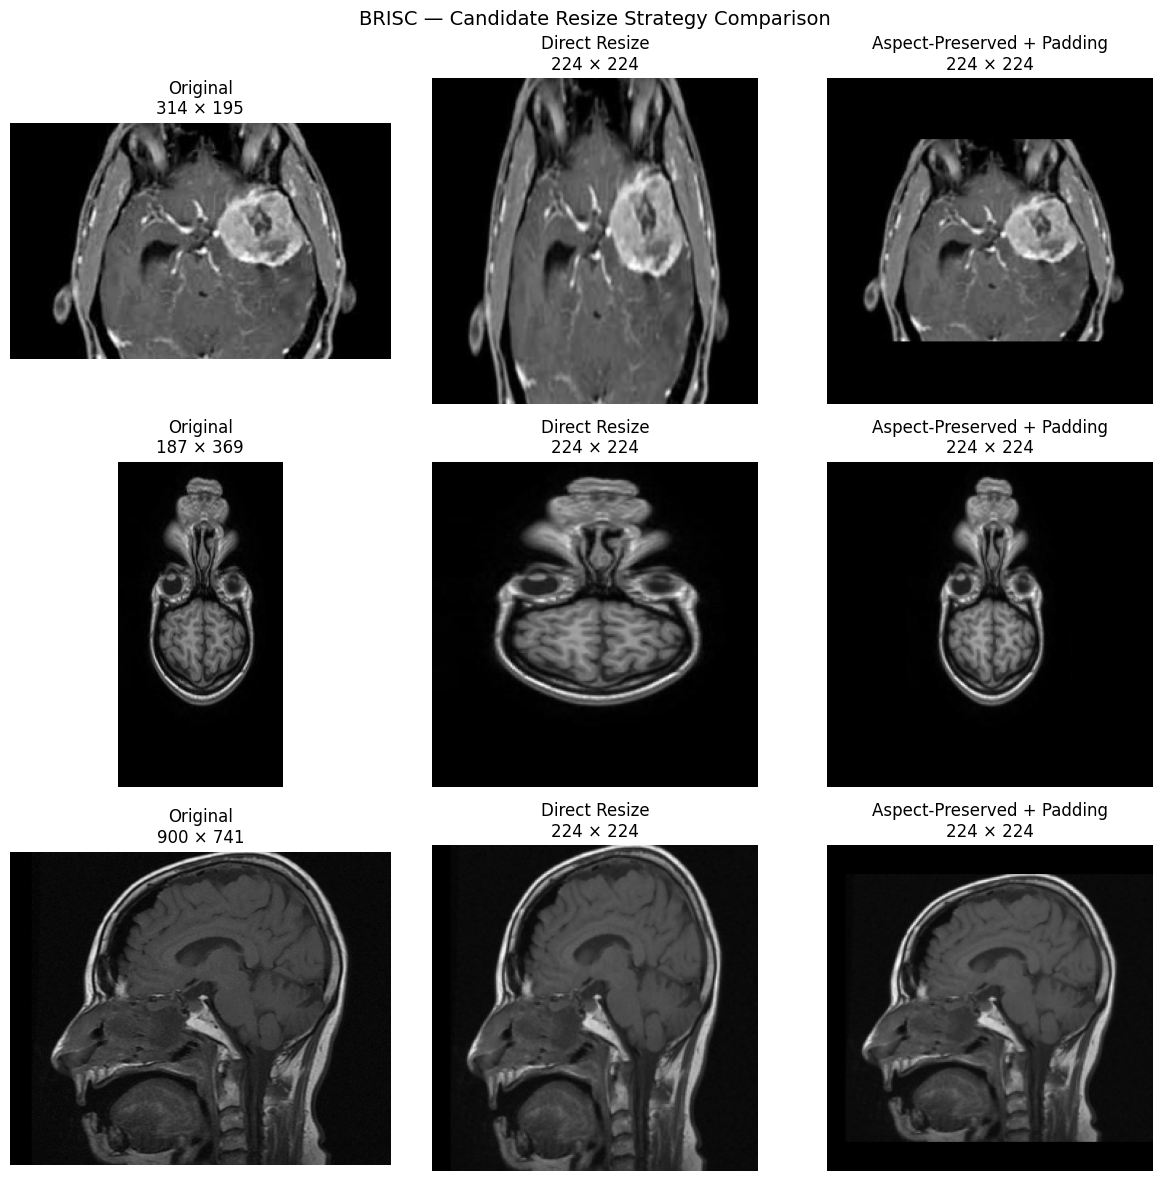

Figure saved to: /Users/krittikaroy/Brain Tumor/outputs/figures/preprocessing_resize_strategy_comparison.png


In [8]:
# Compare direct square resizing with aspect-ratio-preserving padding.

AUDIT_SIZE = 224

def direct_square_resize(img, size=AUDIT_SIZE):
    return img.resize(
        (size, size),
        resample=Image.Resampling.BILINEAR
    )

def aspect_preserving_pad(img, size=AUDIT_SIZE):
    resized = img.copy()
    resized.thumbnail(
        (size, size),
        resample=Image.Resampling.BILINEAR
    )

    canvas = Image.new("L", (size, size), color=0)

    left = (size - resized.width) // 2
    top = (size - resized.height) // 2

    canvas.paste(resized, (left, top))
    return canvas

# Select the most non-square example from each available class
non_square_df = classification_geometry_df[
    ~classification_geometry_df["is_square"]
].copy()

if non_square_df.empty:
    print("No non-square images found. Resize comparison is not required.")
else:
    non_square_df["aspect_deviation"] = (
        non_square_df["aspect_ratio"] - 1
    ).abs()

    audit_samples = (
        non_square_df
        .sort_values("aspect_deviation", ascending=False)
        .groupby("tumor_label", sort=True)
        .head(1)
        .reset_index(drop=True)
    )

    print("Representative non-square images:", len(audit_samples))

    fig, axes = plt.subplots(
        len(audit_samples),
        3,
        figsize=(12, 4 * len(audit_samples))
    )

    axes = np.atleast_2d(axes)

    for row_index, sample in audit_samples.iterrows():

        image_path = DATASET_ROOT / sample["relative_path"]

        with Image.open(image_path) as img:
            gray = img.convert("L")
            direct = direct_square_resize(gray)
            padded = aspect_preserving_pad(gray)

        images = [gray, direct, padded]

        titles = [
            f"Original\n{gray.width} × {gray.height}",
            f"Direct Resize\n{AUDIT_SIZE} × {AUDIT_SIZE}",
            f"Aspect-Preserved + Padding\n{AUDIT_SIZE} × {AUDIT_SIZE}"
        ]

        for col in range(3):
            axes[row_index, col].imshow(
                images[col],
                cmap="gray"
            )
            axes[row_index, col].set_title(titles[col])
            axes[row_index, col].axis("off")

        axes[row_index, 0].set_ylabel(
            sample["tumor_label"],
            fontsize=10
        )

    plt.suptitle(
        "BRISC — Candidate Resize Strategy Comparison",
        fontsize=14
    )
    plt.tight_layout()

    resize_audit_path = (
        FIGURES_ROOT / "preprocessing_resize_strategy_comparison.png"
    )

    plt.savefig(
        resize_audit_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Figure saved to:", resize_audit_path)

In [9]:
# Define a conservative function to identify and trim external dark margins for auditing.

BACKGROUND_THRESHOLD = 10
CROP_MARGIN_FRACTION = 0.03

def trim_dark_background(
    img,
    threshold=BACKGROUND_THRESHOLD,
    margin_fraction=CROP_MARGIN_FRACTION
):
    # Convert image to grayscale
    gray = img.convert("L")
    arr = np.asarray(gray)

    # Identify pixels brighter than the near-black threshold
    foreground = arr > threshold

    # Retain the original if no foreground pixels are found
    if not foreground.any():
        return gray.copy()

    # Find bounding coordinates
    rows, cols = np.where(foreground)

    top = int(rows.min())
    bottom = int(rows.max()) + 1
    left = int(cols.min())
    right = int(cols.max()) + 1

    # Add a small safety margin around the detected region
    box_width = right - left
    box_height = bottom - top

    margin_x = int(round(box_width * margin_fraction))
    margin_y = int(round(box_height * margin_fraction))

    left = max(0, left - margin_x)
    right = min(gray.width, right + margin_x)
    top = max(0, top - margin_y)
    bottom = min(gray.height, bottom + margin_y)

    return gray.crop((left, top, right, bottom))


print("Dark-background trimming function defined.")
print("Threshold:", BACKGROUND_THRESHOLD)
print("Safety margin:", CROP_MARGIN_FRACTION)
print("Original dataset images remain unchanged.")

Dark-background trimming function defined.
Threshold: 10
Safety margin: 0.03
Original dataset images remain unchanged.


In [10]:
# Audit how conservative dark-background trimming changes classification image dimensions.

trimmed_geometry_records = []

print("AUDITING FOREGROUND-AWARE IMAGE GEOMETRY")
print("-" * 60)
print("Images to inspect:", len(master_split_df))

for i, row in master_split_df.iterrows():

    image_path = DATASET_ROOT / row["relative_path_posix"]

    with Image.open(image_path) as img:
        gray = img.convert("L")
        trimmed = trim_dark_background(gray)

        original_width, original_height = gray.size
        trimmed_width, trimmed_height = trimmed.size

    trimmed_geometry_records.append({
        "filename": row["filename"],
        "model_split": row["model_split"],
        "tumor_label": row["tumor_label"],
        "plane_label": row["plane_label"],
        "original_width": original_width,
        "original_height": original_height,
        "trimmed_width": trimmed_width,
        "trimmed_height": trimmed_height,
        "original_aspect_ratio": original_width / original_height,
        "trimmed_aspect_ratio": trimmed_width / trimmed_height,
        "width_removed_percent": (
            100 * (original_width - trimmed_width) / original_width
        ),
        "height_removed_percent": (
            100 * (original_height - trimmed_height) / original_height
        )
    })

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(master_split_df)}")

trimmed_geometry_df = pd.DataFrame(trimmed_geometry_records)

assert len(trimmed_geometry_df) == len(master_split_df)

print("\nForeground framing audit complete.")
print("Images inspected:", len(trimmed_geometry_df))

AUDITING FOREGROUND-AWARE IMAGE GEOMETRY
------------------------------------------------------------
Images to inspect: 5862
Processed 500/5862
Processed 1000/5862
Processed 1500/5862
Processed 2000/5862
Processed 2500/5862
Processed 3000/5862
Processed 3500/5862
Processed 4000/5862
Processed 4500/5862
Processed 5000/5862
Processed 5500/5862

Foreground framing audit complete.
Images inspected: 5862


In [11]:
# Summarize original and trimmed image geometry across all classification images.

print("FOREGROUND-AWARE GEOMETRY SUMMARY")
print("-" * 65)

print("\nORIGINAL ASPECT RATIOS")
display(
    trimmed_geometry_df["original_aspect_ratio"]
    .describe()
    .round(4)
    .to_frame()
)

print("\nASPECT RATIOS AFTER DARK-BACKGROUND TRIMMING")
display(
    trimmed_geometry_df["trimmed_aspect_ratio"]
    .describe()
    .round(4)
    .to_frame()
)

print("\nTRIMMED ASPECT RATIO BY TUMOR CLASS")
trimmed_class_summary = (
    trimmed_geometry_df
    .groupby("tumor_label")["trimmed_aspect_ratio"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)
display(trimmed_class_summary)

print("\nAMOUNT OF IMAGE CANVAS REMOVED")
display(
    trimmed_geometry_df[
        ["width_removed_percent", "height_removed_percent"]
    ]
    .describe()
    .round(2)
)

# Save audit summaries
trimmed_geometry_df.to_csv(
    TABLES_ROOT / "classification_trimmed_geometry_audit.csv",
    index=False
)

trimmed_class_summary.to_csv(
    TABLES_ROOT / "classification_trimmed_aspect_ratio_by_class.csv"
)

print("\nAudit summaries saved successfully.")

FOREGROUND-AWARE GEOMETRY SUMMARY
-----------------------------------------------------------------

ORIGINAL ASPECT RATIOS


,original_aspect_ratio
count,5862.0000
mean,0.9697
std,0.1104
min,0.5068
25%,1.0000
50%,1.0000
75%,1.0000
max,1.6103



ASPECT RATIOS AFTER DARK-BACKGROUND TRIMMING


,trimmed_aspect_ratio
count,5862.0000
mean,0.9579
std,0.1361
min,0.4557
25%,0.9004
50%,1.0000
75%,1.0262
max,1.6765



TRIMMED ASPECT RATIO BY TUMOR CLASS


,count,mean,median,min,max
tumor_label,,,,,
glioma,1401,0.9534,0.9300,0.6787,1.6765
meningioma,1523,1.0066,1.0059,0.6844,1.5827
no_tumor,1198,0.8529,0.9274,0.4557,1.4000
pituitary,1740,0.9912,1.0000,0.7883,1.1795



AMOUNT OF IMAGE CANVAS REMOVED


,width_removed_percent,height_removed_percent
count,5862.00,5862.00
mean,9.30,8.15
std,10.55,8.20
min,0.00,0.00
25%,0.00,0.59
50%,4.27,6.23
75%,17.77,12.70
max,47.46,53.52



Audit summaries saved successfully.


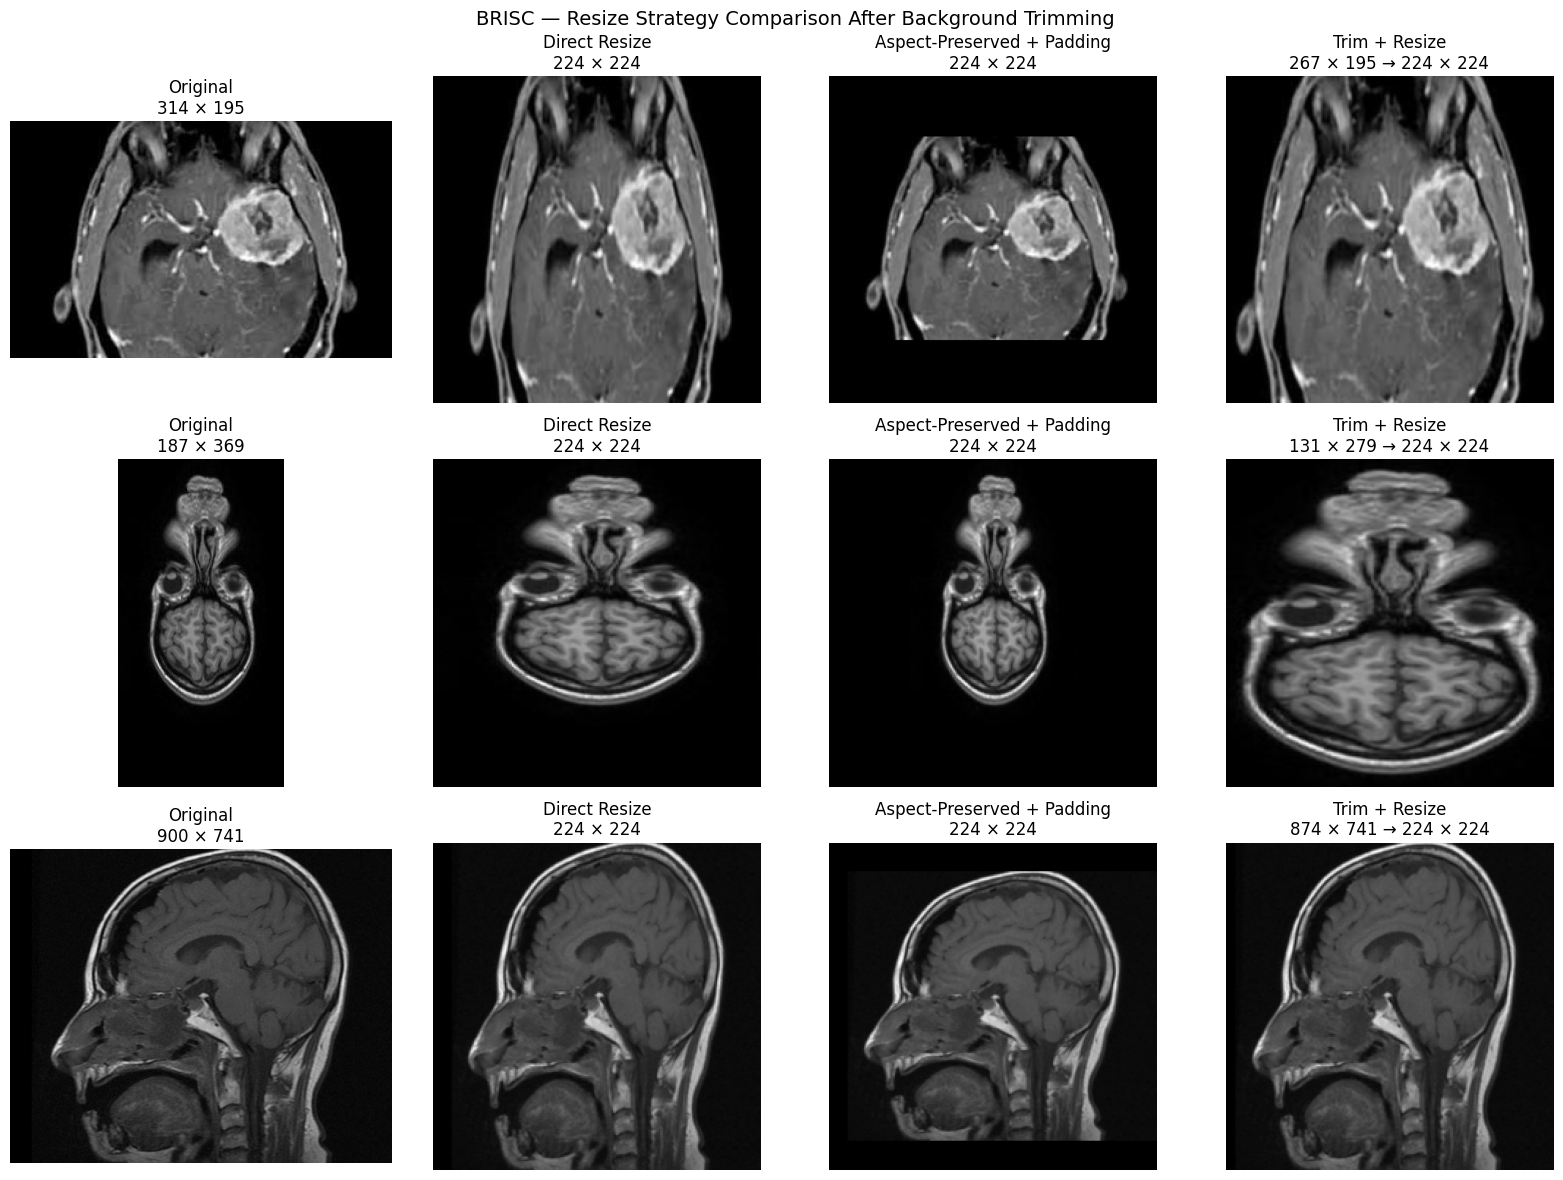

Figure saved to: /Users/krittikaroy/Brain Tumor/outputs/figures/preprocessing_background_trim_resize_comparison.png


In [12]:
# Visually compare resizing methods before finalizing classification preprocessing.

non_square_df = classification_geometry_df[
    ~classification_geometry_df["is_square"]
].copy()

non_square_df["aspect_deviation"] = (
    non_square_df["aspect_ratio"] - 1
).abs()

# Select the most non-square example from each available class
trim_audit_samples = (
    non_square_df
    .sort_values("aspect_deviation", ascending=False)
    .groupby("tumor_label")
    .head(1)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    len(trim_audit_samples),
    4,
    figsize=(16, 4 * len(trim_audit_samples))
)

axes = np.atleast_2d(axes)

for row_index, sample in trim_audit_samples.iterrows():

    source_row = master_split_df[
        master_split_df["filename"] == sample["filename"]
    ].iloc[0]

    image_path = DATASET_ROOT / source_row["relative_path_posix"]

    with Image.open(image_path) as img:
        gray = img.convert("L")

        direct = direct_square_resize(gray)
        padded = aspect_preserving_pad(gray)

        trimmed = trim_dark_background(gray)
        trimmed_square = direct_square_resize(trimmed)

    images = [gray, direct, padded, trimmed_square]

    titles = [
        f"Original\n{gray.width} × {gray.height}",
        "Direct Resize\n224 × 224",
        "Aspect-Preserved + Padding\n224 × 224",
        f"Trim + Resize\n{trimmed.width} × {trimmed.height} → 224 × 224"
    ]

    for col in range(4):
        axes[row_index, col].imshow(images[col], cmap="gray")
        axes[row_index, col].set_title(titles[col])
        axes[row_index, col].axis("off")

    axes[row_index, 0].set_ylabel(
        sample["tumor_label"],
        fontsize=10
    )

plt.suptitle(
    "BRISC — Resize Strategy Comparison After Background Trimming",
    fontsize=14
)

plt.tight_layout()

trim_resize_figure_path = (
    FIGURES_ROOT / "preprocessing_background_trim_resize_comparison.png"
)

plt.savefig(
    trim_resize_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", trim_resize_figure_path)

In [13]:
# Define the canonical classification preprocessing configuration.

DEFAULT_INPUT_SIZE = 224

CLASSIFICATION_PREPROCESSING_CONFIG = {
    "canonical_mode": "L",
    "spatial_method": "direct_square_resize",
    "default_input_size": DEFAULT_INPUT_SIZE,
    "resize_interpolation": "bilinear",
    "background_trimming": False,
    "aspect_ratio_padding": False,
    "output_value_range": "0_to_1",
    "three_channel_policy": "replicate_grayscale_if_required"
}

print("CLASSIFICATION PREPROCESSING CONFIGURATION")
print("-" * 60)

for key, value in CLASSIFICATION_PREPROCESSING_CONFIG.items():
    print(f"{key}: {value}")

CLASSIFICATION PREPROCESSING CONFIGURATION
------------------------------------------------------------
canonical_mode: L
spatial_method: direct_square_resize
default_input_size: 224
resize_interpolation: bilinear
background_trimming: False
aspect_ratio_padding: False
output_value_range: 0_to_1
three_channel_policy: replicate_grayscale_if_required


In [14]:
# Define the reusable deterministic preprocessing function for classification MRI images.

def preprocess_classification_image(
    image_path,
    target_size=DEFAULT_INPUT_SIZE,
    output_channels=1
):
    """
    Preprocess a BRISC classification MRI image.

    Steps:
    1. Load the original image.
    2. Convert it to grayscale.
    3. Directly resize it to a square target size.
    4. Scale pixel values to [0, 1].
    5. Optionally replicate grayscale into three channels.
    """

    if output_channels not in (1, 3):
        raise ValueError("output_channels must be either 1 or 3.")

    if not isinstance(target_size, int) or target_size <= 0:
        raise ValueError("target_size must be a positive integer.")

    with Image.open(image_path) as img:

        gray = img.convert("L")

        resized = gray.resize(
            (target_size, target_size),
            resample=Image.Resampling.BILINEAR
        )

        arr = np.asarray(
            resized,
            dtype=np.float32
        ) / 255.0

    if output_channels == 3:
        arr = np.repeat(
            arr[..., np.newaxis],
            3,
            axis=2
        )

    return arr


print("Classification preprocessing function defined successfully.")

Classification preprocessing function defined successfully.


In [15]:
# Test classification preprocessing on representative images from all three splits.

preprocess_test_records = pd.concat(
    [
        train_df.sample(n=3, random_state=42),
        validation_df.sample(n=2, random_state=42),
        test_df.sample(n=2, random_state=42)
    ],
    ignore_index=True
)

preprocess_check_records = []

for _, row in preprocess_test_records.iterrows():

    image_path = DATASET_ROOT / row["relative_path_posix"]

    # Grayscale output
    gray_output = preprocess_classification_image(
        image_path,
        target_size=DEFAULT_INPUT_SIZE,
        output_channels=1
    )

    # Three-channel output
    rgb_output = preprocess_classification_image(
        image_path,
        target_size=DEFAULT_INPUT_SIZE,
        output_channels=3
    )

    rgb_channels_identical = (
        np.array_equal(rgb_output[..., 0], rgb_output[..., 1])
        and np.array_equal(rgb_output[..., 1], rgb_output[..., 2])
    )

    preprocess_check_records.append({
        "filename": row["filename"],
        "model_split": row["model_split"],
        "gray_shape": str(gray_output.shape),
        "rgb_shape": str(rgb_output.shape),
        "gray_min": float(gray_output.min()),
        "gray_max": float(gray_output.max()),
        "dtype": str(gray_output.dtype),
        "rgb_channels_identical": rgb_channels_identical
    })

preprocess_check_df = pd.DataFrame(preprocess_check_records)

print("CLASSIFICATION PREPROCESSING SANITY CHECK")
print("-" * 65)
display(preprocess_check_df)

print("\nSUMMARY")
print("-" * 65)

print(
    "All grayscale shapes correct:",
    (preprocess_check_df["gray_shape"] == "(224, 224)").all()
)

print(
    "All RGB shapes correct:",
    (preprocess_check_df["rgb_shape"] == "(224, 224, 3)").all()
)

print(
    "All replicated RGB channels identical:",
    preprocess_check_df["rgb_channels_identical"].all()
)

print(
    "All values within [0, 1]:",
    bool(
        (preprocess_check_df["gray_min"] >= 0).all()
        and (preprocess_check_df["gray_max"] <= 1).all()
    )
)

print("\nPreprocessing test completed.")

CLASSIFICATION PREPROCESSING SANITY CHECK
-----------------------------------------------------------------


,filename,model_split,gray_shape,rgb_shape,gray_min,gray_max,dtype,rgb_channels_identical
0,brisc2025_train_04376_pi_co_t1.jpg,train,"(224, 224)","(224, 224, 3)",0.0,0.937255,float32,True
1,brisc2025_train_03808_pi_ax_t1.jpg,train,"(224, 224)","(224, 224, 3)",0.0,0.976471,float32,True
2,brisc2025_train_03069_no_co_t1.jpg,train,"(224, 224)","(224, 224, 3)",0.0,0.917647,float32,True
3,brisc2025_train_00948_gl_sa_t1.jpg,validation,"(224, 224)","(224, 224, 3)",0.0,0.847059,float32,True
4,brisc2025_train_03520_no_sa_t1.jpg,validation,"(224, 224)","(224, 224, 3)",0.0,1.000000,float32,True
5,brisc2025_test_00522_me_sa_t1.jpg,test,"(224, 224)","(224, 224, 3)",0.0,0.964706,float32,True
6,brisc2025_test_00738_pi_ax_t1.jpg,test,"(224, 224)","(224, 224, 3)",0.0,0.870588,float32,True



SUMMARY
-----------------------------------------------------------------
All grayscale shapes correct: True
All RGB shapes correct: True
All replicated RGB channels identical: True
All values within [0, 1]: True

Preprocessing test completed.


In [16]:
# Match every segmentation MRI with its corresponding mask and verify metadata.

# Create an MRI lookup table
segmentation_mri_lookup = (
    segmentation_mri_df[
        [
            "relative_path_posix",
            "filename",
            "split",
            "tumor_label",
            "plane_label"
        ]
    ]
    .copy()
    .rename(columns={
        "relative_path_posix": "mri_relative_path",
        "filename": "mri_filename",
        "split": "mri_split",
        "tumor_label": "mri_tumor_label",
        "plane_label": "mri_plane_label"
    })
)

# Create the mask table
segmentation_pairs_df = (
    segmentation_mask_df[
        [
            "relative_path_posix",
            "filename",
            "linked_image_posix",
            "split",
            "tumor_label",
            "plane_label"
        ]
    ]
    .copy()
    .rename(columns={
        "relative_path_posix": "mask_relative_path",
        "filename": "mask_filename"
    })
)

# Match masks to MRI images using the manifest's linked-image paths
segmentation_pairs_df = segmentation_pairs_df.merge(
    segmentation_mri_lookup,
    left_on="linked_image_posix",
    right_on="mri_relative_path",
    how="left",
    validate="many_to_one"
)

print("SEGMENTATION PAIR TABLE")
print("-" * 60)
print("Mask records:", len(segmentation_pairs_df))
print(
    "MRI links resolved:",
    segmentation_pairs_df["mri_relative_path"].notna().sum()
)
print(
    "MRI links missing:",
    segmentation_pairs_df["mri_relative_path"].isna().sum()
)

# Check metadata consistency
split_mismatches = (
    segmentation_pairs_df["split"]
    != segmentation_pairs_df["mri_split"]
).sum()

class_mismatches = (
    segmentation_pairs_df["tumor_label"]
    != segmentation_pairs_df["mri_tumor_label"]
).sum()

plane_mismatches = (
    segmentation_pairs_df["plane_label"]
    != segmentation_pairs_df["mri_plane_label"]
).sum()

print("\nPAIR METADATA CONSISTENCY")
print("-" * 60)
print("Split mismatches:", split_mismatches)
print("Tumor-label mismatches:", class_mismatches)
print("Plane-label mismatches:", plane_mismatches)

# Final verification
assert len(segmentation_pairs_df) == 4793
assert segmentation_pairs_df["mri_relative_path"].notna().all()
assert split_mismatches == 0
assert class_mismatches == 0
assert plane_mismatches == 0

print("\nAll segmentation pair checks PASSED.")

SEGMENTATION PAIR TABLE
------------------------------------------------------------
Mask records: 4793
MRI links resolved: 4793
MRI links missing: 0

PAIR METADATA CONSISTENCY
------------------------------------------------------------
Split mismatches: 0
Tumor-label mismatches: 0
Plane-label mismatches: 0

All segmentation pair checks PASSED.


In [17]:
# Define the deterministic preprocessing configuration for segmentation MRI-mask pairs.

SEGMENTATION_INPUT_SIZE = 224
MASK_THRESHOLD = 128

SEGMENTATION_PREPROCESSING_CONFIG = {
    "mri_canonical_mode": "L",
    "target_size": SEGMENTATION_INPUT_SIZE,
    "mri_resize_interpolation": "bilinear",
    "mask_threshold": MASK_THRESHOLD,
    "mask_resize_interpolation": "nearest",
    "mri_output_range": "0_to_1",
    "mask_output_values": [0, 1]
}

print("SEGMENTATION PREPROCESSING CONFIGURATION")
print("-" * 60)

for key, value in SEGMENTATION_PREPROCESSING_CONFIG.items():
    print(f"{key}: {value}")

SEGMENTATION PREPROCESSING CONFIGURATION
------------------------------------------------------------
mri_canonical_mode: L
target_size: 224
mri_resize_interpolation: bilinear
mask_threshold: 128
mask_resize_interpolation: nearest
mri_output_range: 0_to_1
mask_output_values: [0, 1]


In [18]:
# Define the reusable deterministic preprocessing function for segmentation MRI-mask pairs.

def preprocess_segmentation_pair(
    mri_path,
    mask_path,
    target_size=SEGMENTATION_INPUT_SIZE,
    mri_output_channels=1
):
    """
    Preprocess one BRISC segmentation MRI-mask pair.

    MRI:
        Grayscale -> bilinear resize -> float32 [0, 1]

    Mask:
        Grayscale -> threshold >= 128 -> binary
        -> nearest-neighbor resize -> uint8 {0, 1}
    """

    if mri_output_channels not in (1, 3):
        raise ValueError("mri_output_channels must be either 1 or 3.")

    if not isinstance(target_size, int) or target_size <= 0:
        raise ValueError("target_size must be a positive integer.")

    # Preprocess MRI
    with Image.open(mri_path) as img:
        gray_mri = img.convert("L")

        resized_mri = gray_mri.resize(
            (target_size, target_size),
            resample=Image.Resampling.BILINEAR
        )

        mri_arr = np.asarray(
            resized_mri,
            dtype=np.float32
        ) / 255.0

    if mri_output_channels == 3:
        mri_arr = np.repeat(
            mri_arr[..., np.newaxis],
            3,
            axis=2
        )

    # Preprocess binary segmentation mask
    with Image.open(mask_path) as mask:
        mask_gray = np.asarray(
            mask.convert("L")
        )

    binary_mask = (
        mask_gray >= MASK_THRESHOLD
    ).astype(np.uint8)

    binary_mask_pil = Image.fromarray(
        binary_mask * 255,
        mode="L"
    )

    resized_mask = binary_mask_pil.resize(
        (target_size, target_size),
        resample=Image.Resampling.NEAREST
    )

    mask_arr = (
        np.asarray(resized_mask) >= 128
    ).astype(np.uint8)

    return mri_arr, mask_arr


print("Segmentation preprocessing function defined successfully.")

Segmentation preprocessing function defined successfully.


In [19]:
# Test segmentation preprocessing on eight representative MRI-mask pairs.

segmentation_sample_df = (
    segmentation_pairs_df
    .sample(n=8, random_state=42)
    .reset_index(drop=True)
)

segmentation_check_records = []

for _, row in segmentation_sample_df.iterrows():

    mri_path = DATASET_ROOT / row["mri_relative_path"]
    mask_path = DATASET_ROOT / row["mask_relative_path"]

    mri_arr, mask_arr = preprocess_segmentation_pair(
        mri_path,
        mask_path,
        target_size=SEGMENTATION_INPUT_SIZE,
        mri_output_channels=1
    )

    unique_mask_values = np.unique(mask_arr)

    segmentation_check_records.append({
        "mri_filename": row["mri_filename"],
        "mask_filename": row["mask_filename"],
        "split": row["split"],
        "tumor_label": row["tumor_label"],
        "mri_shape": str(mri_arr.shape),
        "mask_shape": str(mask_arr.shape),
        "mri_min": float(mri_arr.min()),
        "mri_max": float(mri_arr.max()),
        "mri_dtype": str(mri_arr.dtype),
        "mask_dtype": str(mask_arr.dtype),
        "mask_values": str(unique_mask_values.tolist()),
        "foreground_pixels": int(mask_arr.sum())
    })

segmentation_check_df = pd.DataFrame(
    segmentation_check_records
)

print("SEGMENTATION PREPROCESSING SANITY CHECK")
print("-" * 65)
display(segmentation_check_df)

print("\nSUMMARY")
print("-" * 65)

print(
    "All MRI shapes correct:",
    (segmentation_check_df["mri_shape"] == "(224, 224)").all()
)

print(
    "All mask shapes correct:",
    (segmentation_check_df["mask_shape"] == "(224, 224)").all()
)

print(
    "All MRI values within [0, 1]:",
    bool(
        (segmentation_check_df["mri_min"] >= 0).all()
        and (segmentation_check_df["mri_max"] <= 1).all()
    )
)

print(
    "All masks remain binary:",
    all(
        set(np.unique(mask_arr)).issubset({0, 1})
        for mask_arr in [
            preprocess_segmentation_pair(
                DATASET_ROOT / row["mri_relative_path"],
                DATASET_ROOT / row["mask_relative_path"],
                target_size=SEGMENTATION_INPUT_SIZE,
                mri_output_channels=1
            )[1]
            for _, row in segmentation_sample_df.iterrows()
        ]
    )
)

print(
    "All masks contain foreground:",
    (segmentation_check_df["foreground_pixels"] > 0).all()
)

SEGMENTATION PREPROCESSING SANITY CHECK
-----------------------------------------------------------------


/var/folders/nv/x8svc1910h1dybg0v4915h1m0000gn/T/ipykernel_10007/312260813.py:57: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  binary_mask_pil = Image.fromarray(


,mri_filename,mask_filename,split,tumor_label,mri_shape,mask_shape,mri_min,mri_max,mri_dtype,mask_dtype,mask_values,foreground_pixels
0,brisc2025_test_00702_pi_ax_t1.jpg,brisc2025_test_00702_pi_ax_t1.png,test,pituitary,"(224, 224)","(224, 224)",0.0,0.858824,float32,uint8,"[0, 1]",323
1,brisc2025_train_00034_gl_ax_t1.jpg,brisc2025_train_00034_gl_ax_t1.png,train,glioma,"(224, 224)","(224, 224)",0.0,0.854902,float32,uint8,"[0, 1]",984
2,brisc2025_train_00825_gl_sa_t1.jpg,brisc2025_train_00825_gl_sa_t1.png,train,glioma,"(224, 224)","(224, 224)",0.0,0.909804,float32,uint8,"[0, 1]",476
3,brisc2025_test_00846_pi_co_t1.jpg,brisc2025_test_00846_pi_co_t1.png,test,pituitary,"(224, 224)","(224, 224)",0.0,0.843137,float32,uint8,"[0, 1]",410
4,brisc2025_train_01014_gl_sa_t1.jpg,brisc2025_train_01014_gl_sa_t1.png,train,glioma,"(224, 224)","(224, 224)",0.0,0.894118,float32,uint8,"[0, 1]",1091
5,brisc2025_train_01837_me_co_t1.jpg,brisc2025_train_01837_me_co_t1.png,train,meningioma,"(224, 224)","(224, 224)",0.0,0.925490,float32,uint8,"[0, 1]",1199
6,brisc2025_train_02158_me_sa_t1.jpg,brisc2025_train_02158_me_sa_t1.png,train,meningioma,"(224, 224)","(224, 224)",0.0,0.960784,float32,uint8,"[0, 1]",929
7,brisc2025_train_04687_pi_sa_t1.jpg,brisc2025_train_04687_pi_sa_t1.png,train,pituitary,"(224, 224)","(224, 224)",0.0,0.878431,float32,uint8,"[0, 1]",379



SUMMARY
-----------------------------------------------------------------
All MRI shapes correct: True
All mask shapes correct: True
All MRI values within [0, 1]: True
All masks remain binary: True
All masks contain foreground: True


/var/folders/nv/x8svc1910h1dybg0v4915h1m0000gn/T/ipykernel_10007/312260813.py:57: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  binary_mask_pil = Image.fromarray(


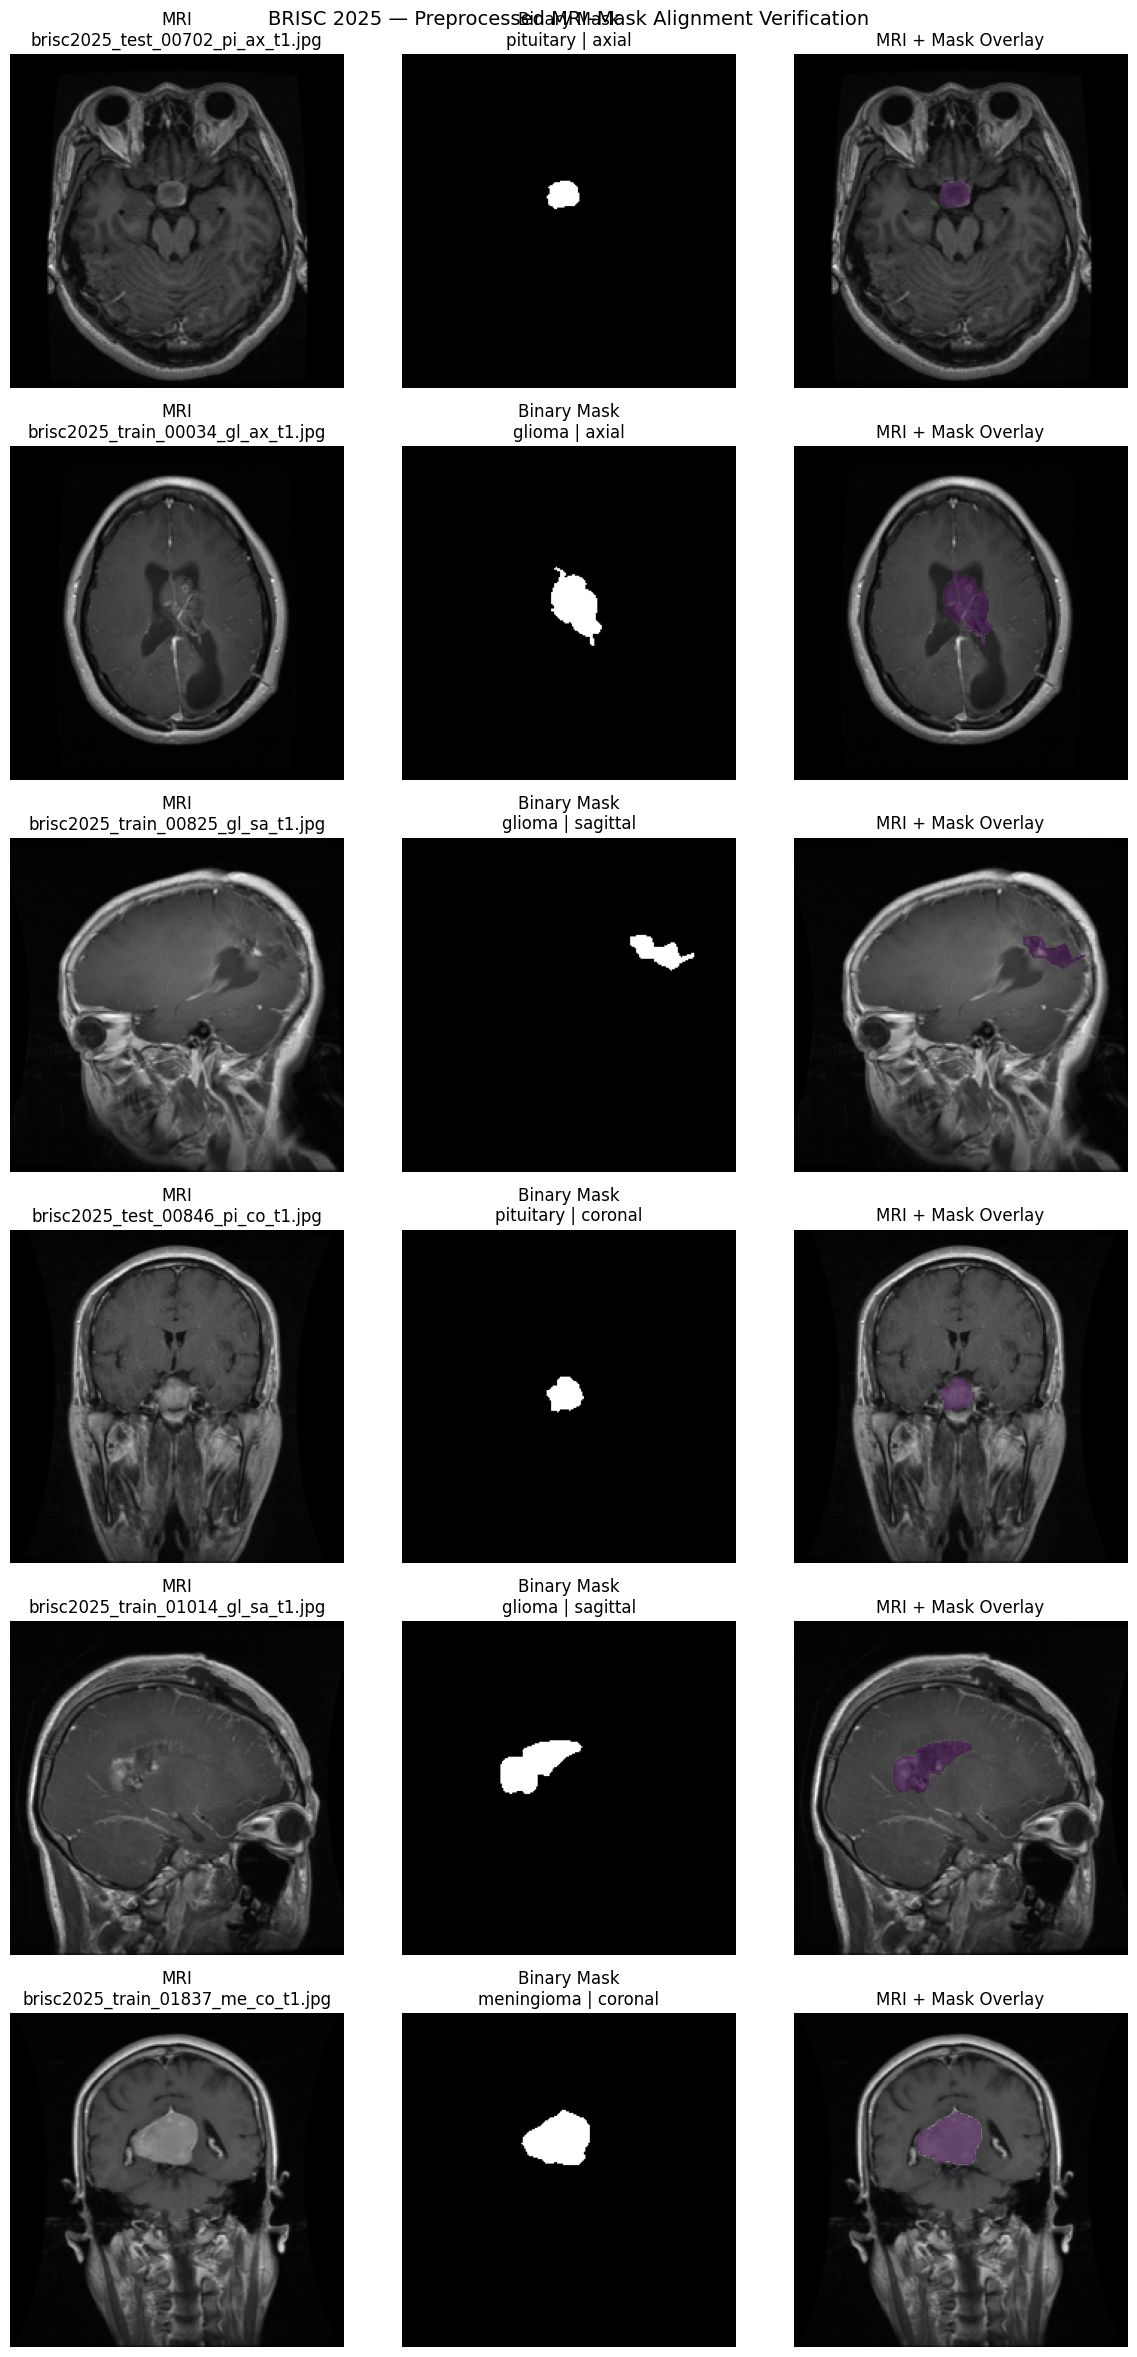

Figure saved to:
/Users/krittikaroy/Brain Tumor/outputs/figures/preprocessing_segmentation_alignment_verification.png


In [20]:
# Visually verify alignment between preprocessed segmentation MRI images and masks.

# Update the function to remove Pillow's deprecated mode argument
def preprocess_segmentation_pair(
    mri_path,
    mask_path,
    target_size=SEGMENTATION_INPUT_SIZE,
    mri_output_channels=1
):
    # Process MRI
    with Image.open(mri_path) as img:
        gray_mri = img.convert("L")
        resized_mri = gray_mri.resize(
            (target_size, target_size),
            resample=Image.Resampling.BILINEAR
        )
        mri_arr = np.asarray(
            resized_mri,
            dtype=np.float32
        ) / 255.0

    if mri_output_channels == 3:
        mri_arr = np.repeat(
            mri_arr[..., np.newaxis], 3, axis=2
        )

    # Process binary mask
    with Image.open(mask_path) as mask:
        mask_gray = np.asarray(mask.convert("L"))

    binary_mask = (
        mask_gray >= MASK_THRESHOLD
    ).astype(np.uint8)

    binary_mask_pil = Image.fromarray(
        binary_mask * 255
    )

    resized_mask = binary_mask_pil.resize(
        (target_size, target_size),
        resample=Image.Resampling.NEAREST
    )

    mask_arr = (
        np.asarray(resized_mask) >= 128
    ).astype(np.uint8)

    return mri_arr, mask_arr


# Select six representative MRI-mask pairs
visual_segmentation_samples = (
    segmentation_pairs_df
    .sample(n=6, random_state=42)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    6, 3,
    figsize=(12, 24)
)

for row_index, row in visual_segmentation_samples.iterrows():

    mri_path = DATASET_ROOT / row["mri_relative_path"]
    mask_path = DATASET_ROOT / row["mask_relative_path"]

    mri_arr, mask_arr = preprocess_segmentation_pair(
        mri_path,
        mask_path,
        target_size=SEGMENTATION_INPUT_SIZE,
        mri_output_channels=1
    )

    # Display MRI
    axes[row_index, 0].imshow(mri_arr, cmap="gray")
    axes[row_index, 0].set_title(
        f"MRI\n{row['mri_filename']}"
    )

    # Display binary mask
    axes[row_index, 1].imshow(mask_arr, cmap="gray")
    axes[row_index, 1].set_title(
        f"Binary Mask\n{row['tumor_label']} | {row['plane_label']}"
    )

    # Display overlay
    axes[row_index, 2].imshow(mri_arr, cmap="gray")

    masked_overlay = np.ma.masked_where(
        mask_arr == 0,
        mask_arr
    )

    axes[row_index, 2].imshow(
        masked_overlay,
        alpha=0.45
    )

    axes[row_index, 2].set_title("MRI + Mask Overlay")

    for column in range(3):
        axes[row_index, column].axis("off")

plt.suptitle(
    "BRISC 2025 — Preprocessed MRI–Mask Alignment Verification",
    fontsize=14
)

plt.tight_layout()

alignment_figure_path = (
    FIGURES_ROOT /
    "preprocessing_segmentation_alignment_verification.png"
)

plt.savefig(
    alignment_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(alignment_figure_path)

In [21]:
# Measure tumor-area preservation before and after resizing all segmentation masks.

area_preservation_records = []

print("AUDITING TUMOR-AREA PRESERVATION")
print("-" * 65)
print("Masks to process:", len(segmentation_pairs_df))

for i, row in segmentation_pairs_df.iterrows():

    mask_path = DATASET_ROOT / row["mask_relative_path"]

    # Load original mask and convert it to binary
    with Image.open(mask_path) as mask:
        original_mask = np.asarray(mask.convert("L"))

    original_binary = (
        original_mask >= MASK_THRESHOLD
    ).astype(np.uint8)

    original_foreground_percent = (
        100 * original_binary.sum() / original_binary.size
    )

    # Resize binary mask using nearest-neighbor interpolation
    binary_mask_pil = Image.fromarray(original_binary * 255)

    resized_mask = binary_mask_pil.resize(
        (SEGMENTATION_INPUT_SIZE, SEGMENTATION_INPUT_SIZE),
        resample=Image.Resampling.NEAREST
    )

    resized_binary = (
        np.asarray(resized_mask) >= 128
    ).astype(np.uint8)

    resized_foreground_percent = (
        100 * resized_binary.sum() / resized_binary.size
    )

    absolute_difference = abs(
        resized_foreground_percent - original_foreground_percent
    )

    relative_difference_percent = (
        100 * absolute_difference / original_foreground_percent
        if original_foreground_percent > 0
        else np.nan
    )

    area_preservation_records.append({
        "mask_filename": row["mask_filename"],
        "split": row["split"],
        "tumor_label": row["tumor_label"],
        "plane_label": row["plane_label"],
        "original_foreground_percent": original_foreground_percent,
        "resized_foreground_percent": resized_foreground_percent,
        "absolute_difference_pct_points": absolute_difference,
        "relative_difference_percent": relative_difference_percent
    })

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(segmentation_pairs_df)}")

area_preservation_df = pd.DataFrame(area_preservation_records)

assert len(area_preservation_df) == 4793

# Save the complete audit
area_preservation_path = (
    TABLES_ROOT / "segmentation_tumor_area_preservation.csv"
)

area_preservation_df.to_csv(area_preservation_path, index=False)

print("\nTumor-area preservation audit complete.")
print("Records:", len(area_preservation_df))
print("Saved to:", area_preservation_path)

AUDITING TUMOR-AREA PRESERVATION
-----------------------------------------------------------------
Masks to process: 4793
Processed 500/4793
Processed 1000/4793
Processed 1500/4793
Processed 2000/4793
Processed 2500/4793
Processed 3000/4793
Processed 3500/4793
Processed 4000/4793
Processed 4500/4793

Tumor-area preservation audit complete.
Records: 4793
Saved to: /Users/krittikaroy/Brain Tumor/outputs/tables/segmentation_tumor_area_preservation.csv


In [22]:
# Summarize how accurately nearest-neighbor resizing preserves tumor area.

print("TUMOR-AREA PRESERVATION SUMMARY")
print("-" * 70)

display(
    area_preservation_df[
        [
            "original_foreground_percent",
            "resized_foreground_percent",
            "absolute_difference_pct_points",
            "relative_difference_percent"
        ]
    ]
    .describe()
    .round(4)
)

print("\nABSOLUTE DIFFERENCE THRESHOLDS")
print("-" * 70)

for threshold in [0.01, 0.05, 0.10, 0.25, 0.50]:
    count = (
        area_preservation_df[
            "absolute_difference_pct_points"
        ] > threshold
    ).sum()

    print(f"> {threshold:.2f} percentage points:", count)

print("\nMEAN ABSOLUTE DIFFERENCE BY CLASS")
print("-" * 70)

display(
    area_preservation_df
    .groupby("tumor_label")[
        "absolute_difference_pct_points"
    ]
    .agg(["count", "mean", "median", "max"])
    .round(4)
)

print("\nCORRELATION BETWEEN ORIGINAL AND RESIZED TUMOR AREA")
print("-" * 70)

area_correlation = (
    area_preservation_df[
        [
            "original_foreground_percent",
            "resized_foreground_percent"
        ]
    ]
    .corr()
    .iloc[0, 1]
)

print("Pearson correlation:", round(area_correlation, 6))

TUMOR-AREA PRESERVATION SUMMARY
----------------------------------------------------------------------


,original_foreground_percent,resized_foreground_percent,absolute_difference_pct_points,relative_difference_percent
count,4793.0000,4793.0000,4793.0000,4793.0000
mean,1.6937,1.6951,0.0070,0.6229
std,1.4973,1.4982,0.0073,0.7123
min,0.0088,0.0080,0.0000,0.0000
25%,0.7099,0.7115,0.0024,0.1845
50%,1.2554,1.2556,0.0052,0.4076
75%,2.1439,2.1504,0.0092,0.7979
max,17.3472,17.3330,0.1096,9.2393



ABSOLUTE DIFFERENCE THRESHOLDS
----------------------------------------------------------------------
> 0.01 percentage points: 1042
> 0.05 percentage points: 20
> 0.10 percentage points: 2
> 0.25 percentage points: 0
> 0.50 percentage points: 0

MEAN ABSOLUTE DIFFERENCE BY CLASS
----------------------------------------------------------------------


,count,mean,median,max
tumor_label,,,,
glioma,1401,0.0067,0.0053,0.0393
meningioma,1635,0.0087,0.0061,0.1096
pituitary,1757,0.0055,0.0044,0.0350



CORRELATION BETWEEN ORIGINAL AND RESIZED TUMOR AREA
----------------------------------------------------------------------
Pearson correlation: 0.999978


In [23]:
# Define the conservative training-only augmentation policy.

AUGMENTATION_POLICY = {
    "apply_to_train_only": True,
    "apply_to_validation": False,
    "apply_to_test": False,

    "rotation_degrees": (-7, 7),

    "translation_fraction": {
        "horizontal": 0.05,
        "vertical": 0.05
    },

    "scale_range": (0.95, 1.05),

    "brightness_factor_range": (0.95, 1.05),
    "contrast_factor_range": (0.95, 1.05),

    "horizontal_flip": False,
    "vertical_flip": False,

    "elastic_deformation": False,
    "random_crop": False,

    "segmentation_spatial_sync_required": True,
    "segmentation_mask_interpolation": "nearest"
}

print("TRAINING-ONLY AUGMENTATION POLICY")
print("-" * 65)

for key, value in AUGMENTATION_POLICY.items():
    print(f"{key}: {value}")

TRAINING-ONLY AUGMENTATION POLICY
-----------------------------------------------------------------
apply_to_train_only: True
apply_to_validation: False
apply_to_test: False
rotation_degrees: (-7, 7)
translation_fraction: {'horizontal': 0.05, 'vertical': 0.05}
scale_range: (0.95, 1.05)
brightness_factor_range: (0.95, 1.05)
contrast_factor_range: (0.95, 1.05)
horizontal_flip: False
vertical_flip: False
elastic_deformation: False
random_crop: False
segmentation_spatial_sync_required: True
segmentation_mask_interpolation: nearest


In [24]:
# Save the complete reproducible preprocessing configuration for downstream models.

import json

PREPROCESSING_CONFIG = {
    "classification": {
        **CLASSIFICATION_PREPROCESSING_CONFIG,
        "input_size_status": "224_default_configurable_until_model_selection"
    },

    "segmentation": {
        **SEGMENTATION_PREPROCESSING_CONFIG,
        "input_size_status": "224_default_configurable_until_model_selection"
    },

    "augmentation": AUGMENTATION_POLICY,

    "normalization": {
        "canonical_dataset_scaling": "0_to_1",
        "architecture_specific_normalization": "deferred_to_model_pipeline"
    }
}

preprocessing_config_path = (
    PROCESSED_ROOT / "brisc_preprocessing_config.json"
)

with open(preprocessing_config_path, "w", encoding="utf-8") as f:
    json.dump(PREPROCESSING_CONFIG, f, indent=4)

print("PREPROCESSING CONFIGURATION SAVED")
print("-" * 65)
print("File:", preprocessing_config_path)
print("File exists:", preprocessing_config_path.exists())

PREPROCESSING CONFIGURATION SAVED
-----------------------------------------------------------------
File: /Users/krittikaroy/Brain Tumor/data/processed/brisc_preprocessing_config.json
File exists: True


In [25]:
# Perform final verification before handing the preprocessed dataset to model development.

import json

print("FINAL PREPROCESSING HANDOFF VERIFICATION")
print("=" * 70)

# 1. Reload the saved configuration
with open(preprocessing_config_path, "r", encoding="utf-8") as f:
    saved_preprocessing_config = json.load(f)

assert preprocessing_config_path.exists()
print("Saved preprocessing configuration: PASSED")

# 2. Verify fixed classification manifests
required_manifest_paths = {
    "train": TRAIN_MANIFEST_PATH,
    "validation": VALIDATION_MANIFEST_PATH,
    "test": TEST_MANIFEST_PATH,
    "master": MASTER_SPLIT_PATH
}

for name, path in required_manifest_paths.items():
    assert path.exists(), f"Missing {name} manifest: {path}"

assert len(train_df) == 3889
assert len(validation_df) == 973
assert len(test_df) == 1000
assert len(master_split_df) == 5862

print("Fixed classification manifests and split sizes: PASSED")

# 3. Verify segmentation MRI-mask pairs
assert len(segmentation_pairs_df) == 4793
assert segmentation_pairs_df["mri_relative_path"].notna().all()

print("Segmentation MRI-mask pairing: PASSED")

# 4. Verify classification preprocessing policy
classification_config = saved_preprocessing_config["classification"]

assert classification_config["canonical_mode"] == "L"
assert classification_config["spatial_method"] == "direct_square_resize"
assert classification_config["three_channel_policy"] == (
    "replicate_grayscale_if_required"
)

print("Classification preprocessing policy: PASSED")

# 5. Verify segmentation preprocessing policy
segmentation_config = saved_preprocessing_config["segmentation"]

assert segmentation_config["mask_threshold"] == 128
assert segmentation_config["mask_resize_interpolation"] == "nearest"
assert segmentation_config["mri_resize_interpolation"] == "bilinear"

print("Segmentation preprocessing policy: PASSED")

# 6. Verify augmentation is restricted to training
augmentation_config = saved_preprocessing_config["augmentation"]

assert augmentation_config["apply_to_train_only"] is True
assert augmentation_config["apply_to_validation"] is False
assert augmentation_config["apply_to_test"] is False

print("Training-only augmentation policy: PASSED")

# 7. Verify tumor-area preservation
assert len(area_preservation_df) == 4793
assert area_correlation > 0.999

assert (
    area_preservation_df["absolute_difference_pct_points"].max()
    < 0.25
)

print("Segmentation tumor-area preservation: PASSED")
print("Pearson correlation:", round(area_correlation, 6))

print("\n" + "=" * 70)
print("ALL PREPROCESSING HANDOFF CHECKS PASSED.")
print("=" * 70)

FINAL PREPROCESSING HANDOFF VERIFICATION
Saved preprocessing configuration: PASSED
Fixed classification manifests and split sizes: PASSED
Segmentation MRI-mask pairing: PASSED
Classification preprocessing policy: PASSED
Segmentation preprocessing policy: PASSED
Training-only augmentation policy: PASSED
Segmentation tumor-area preservation: PASSED
Pearson correlation: 0.999978

ALL PREPROCESSING HANDOFF CHECKS PASSED.


In [ ]:
# Notebook 5 — Conclusion

BRISC preprocessing design and validation are complete.

## 1. Classification

The fixed leakage-controlled manifests produced in Notebook 04 are used without creating new splits:

- Training: 3,889 images
- Validation: 973 images
- Official test: 1,000 images

The RGB-channel audit confirmed that all 3,001 RGB-encoded images have identical red, green, and blue channels. Therefore, all classification MRI images can be standardized to grayscale without losing genuine colour information.

The selected deterministic classification preprocessing pipeline is:

1. Load the MRI image.
2. Convert it to grayscale.
3. Directly resize to a configurable square resolution.
4. Scale pixel intensities to [0, 1].
5. Replicate the grayscale channel only when a downstream model requires three-channel input.

The default input size is 224 × 224. This remains configurable until the final model architectures are selected.

## 2. Segmentation

All 4,793 MRI–mask pairs were reconstructed and verified.

The deterministic segmentation preprocessing pipeline is:

- **MRI:** Grayscale → Bilinear resizing → Float32 values in [0, 1].
- **Mask:** Threshold at 128 → Binary representation {0, 1} → Nearest-neighbor resizing.

Visual inspection of representative MRI–mask overlays showed good spatial alignment after preprocessing.

Quantitative tumor-area preservation was evaluated across all 4,793 masks:

- Mean absolute area difference: 0.0070 percentage points.
- Pearson correlation: 0.999978.
- Only 20 masks differed by more than 0.05 percentage points.
- Only 2 masks differed by more than 0.10 percentage points.
- No masks differed by more than 0.25 percentage points.

These results support the selected nearest-neighbor mask resizing strategy.

## 3. Data Augmentation and Normalization

Deterministic preprocessing is applied consistently across training, validation, and test data.

Random augmentation is restricted to the training subset. The initial policy uses conservative rotations, translations, scaling, brightness, and contrast variations.

Horizontal and vertical flips, aggressive cropping, and elastic deformation are disabled by default.

Dataset-level intensity scaling is standardized to [0, 1]. Additional architecture-specific normalization will be incorporated later into the respective model pipelines.

The augmentation policy is defined in this notebook; its actual application will be implemented in the downstream training data loader with synchronized MRI–mask transformations for segmentation.

## 4. Configuration and Handoff

The preprocessing configuration has been exported to:

`data/processed/brisc_preprocessing_config.json`

The final handoff verification confirmed:

- Fixed classification split sizes and membership.
- Segmentation MRI–mask pairing.
- Classification preprocessing configuration.
- Segmentation preprocessing configuration.
- Training-only augmentation policy.
- Tumor-area preservation results.

All final handoff verification checks passed.

The preprocessing functions and configuration are now ready for integration into downstream model-training pipelines. Original dataset images, masks, and official test-set membership remain unchanged.